# Rubidium vapour magnetometry from three complete measured spectra

All86491/83165/85604native samples are actively refitted. Data are real author experimental spectra at nominal input angles0,45,90degrees in a1mm transverse-field cell. Unknowns are field B, vapour temperature T and actual input angle theta. Independent author outcomes are a standard-method comparison, not actual field/temperature truth.

The local ground/excited Hamiltonians contain fine structure, magnetic dipole and electric quadrupole hyperfine terms and electronic/nuclear Zeeman coupling:
$$\mathcal H=C_{\mathrm{FS}}\,\mathbf L\cdot\mathbf S+E_{\mathrm{off}}\mathbf 1+A\,\mathbf I\cdot\mathbf J+B_Q\,\mathcal Q(\mathbf I,\mathbf J)+\mu_B(g_L L_z+g_S S_z+g_I I_z)B.$$
Here I,J,L,S are angular momenta, CFS is the fine-structure coefficient, Eoff the reference-energy offset, A and BQ hyperfine constants, Q the quadrupole operator, muB the Bohr magneton and g factors the magnetic couplings. Eigenvectors give dipole strengths and populations. Thermally broadened complex Voigt profiles give susceptibilities chi for sigma+/sigma-/pi transitions. In the selected transverse Voigt geometry, dielectric eigenmodes give
$$S_0(\nu)=\cos^2\theta\,|e^{in_\parallel k l}|^2+\sin^2\theta\,|e^{in_\perp k l}|^2.$$
Here nu is detuning, k the optical wavenumber, l the cell length and n complex mode indices. Full hyperfine mathematics and propagation remain local.

Normalized S0 is invariant to a common input-field gain. The controlled identifiable gauge Ex=cos(theta),Ey=sin(theta) removes only this nonphysical redundancy. The selected original-supported DE family retains original sine bounds and stopping/budget semantics. This is not unmodified four-variable fit_data: unsuccessful four-variable/ratio/theta LM paths remain archived. Original integer-MHz transition truncation makes the objective weakly nonsmooth. The old single-seed1e-4 response gate failed even between original runs. The replacement protocol was written before an independent third original run and frozen before this fresh reconstruction: unchanged1e-4 response tubes around a finite set of three original outcomes, original parameter and observation-quality limits. This finite empirical optimizer support is not a physical confidence interval.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_data
from src.physics_model import transmission
started=time.perf_counter();fresh,records=run();elapsed=time.perf_counter()-started
print('Full fresh native fit seconds:',elapsed,'Python:',sys.executable)
print(json.dumps(records,indent=2))
np.savez('notebooks/reference_outputs/fresh_measurements.npz',**fresh)
from evaluation.judge import evaluate
report=evaluate(fresh);assert report['passed'],report
print(json.dumps(report,indent=2))
with np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:original={k:z[k] for k in z.files}
data=load_data()


Full fresh native fit seconds: 929.8378267000662 Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
{
  "0": {
    "native_success": true,
    "evaluations": 1260,
    "generations": 59,
    "seconds": 327.29051949991845,
    "rms": 0.0066747713731583475,
    "seed": 20261029,
    "nominal_angle": 0
  },
  "45": {
    "native_success": true,
    "evaluations": 1050,
    "generations": 49,
    "seconds": 281.95924809994176,
    "rms": 0.004083595309833953,
    "seed": 20261029,
    "nominal_angle": 45
  },
  "90": {
    "native_success": true,
    "evaluations": 1281,
    "generations": 60,
    "seconds": 320.57919810002204,
    "rms": 0.00603807631992101,
    "seed": 20261029,
    "nominal_angle": 90
  }
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "magnetic_field_relative_error_0": 3.122210366887159e-07,
    "temperature_absolute_error_0": 3.137406224595907e-05,
    "polarization_absolute_error_0": 4.790306305929581e-07,
    "spe

## Full measured spectra and residual structure

All observations enter each fit; visual lines below retain every sample. Gray dashed lines are the primary original fit; colored lines are fresh. Residual structure is experimental/model mismatch, not proof of hidden physical accuracy. The old failed deterministic reproducibility claim is not reused.

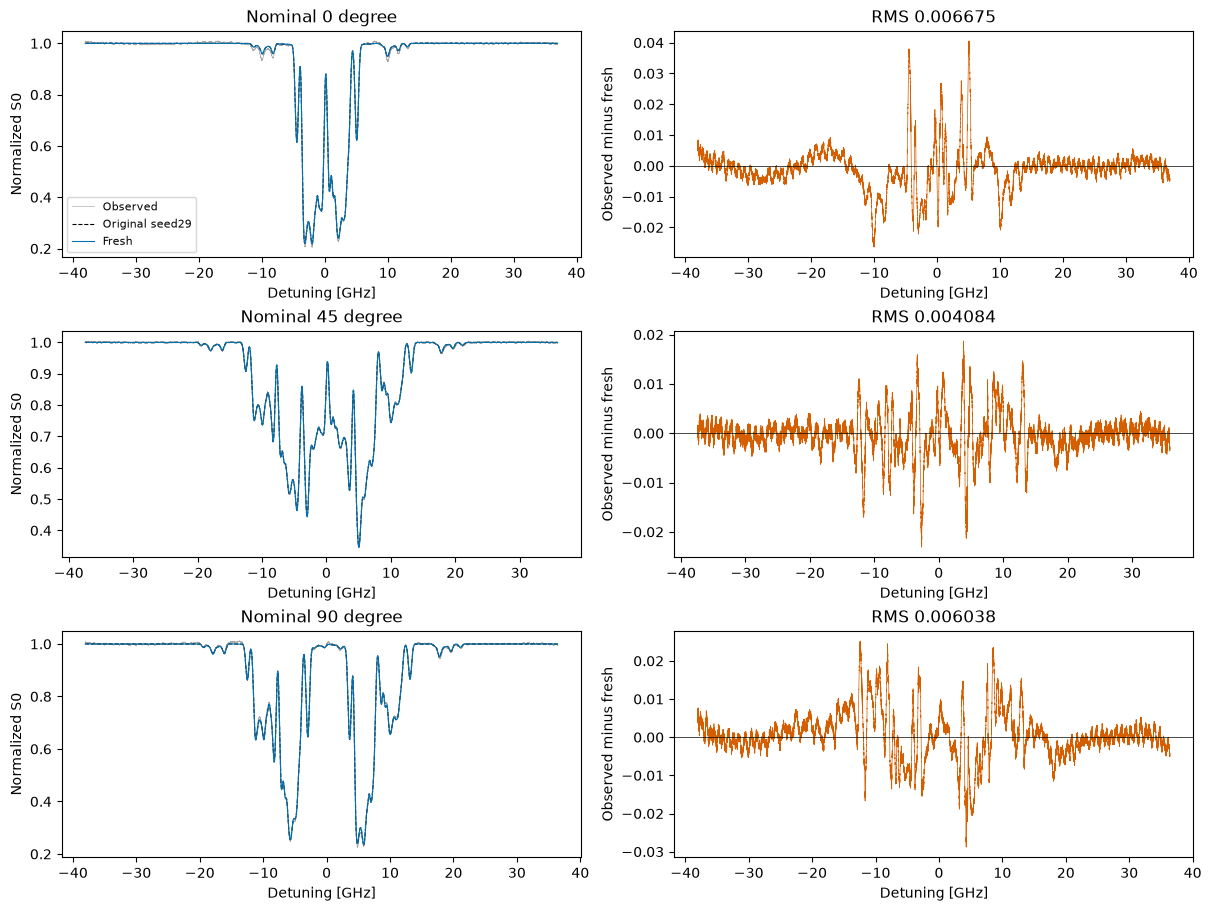

In [2]:
fig,axes=plt.subplots(3,2,figsize=(12,9),layout='constrained')
for i,angle in enumerate([0,45,90]):
    x,y=data[angle];pred=fresh[f'reconstruction_{angle}'][0]
    axes[i,0].plot(x/1000,y,color='.65',lw=.45,label='Observed')
    axes[i,0].plot(x/1000,original[f'response_{angle}_20261029'][0],'--',color='black',lw=.8,label='Original seed29')
    axes[i,0].plot(x/1000,pred,color='#0072B2',lw=.8,label='Fresh')
    axes[i,0].set(ylabel='Normalized S0',title=f'Nominal {angle} degree')
    axes[i,1].plot(x/1000,y-pred,color='#D55E00',lw=.5)
    axes[i,1].axhline(0,color='black',lw=.5);axes[i,1].set(ylabel='Observed minus fresh',title=f'RMS {np.sqrt(np.mean((y-pred)**2)):.6f}')
    axes[i,0].set_xlabel('Detuning [GHz]');axes[i,1].set_xlabel('Detuning [GHz]')
axes[0,0].legend(fontsize=8)
fig.savefig('output/elecsus_spectra.png',dpi=150);plt.show()


## Physical parameter stability under stochastic optimization

Three independent original DE outcomes are a finite empirical support set. These markers are not physical confidence limits. Fresh parameters are evaluated in tesla,kelvin,radians. Nominal polarization labels describe acquisition, not true fitted angles.

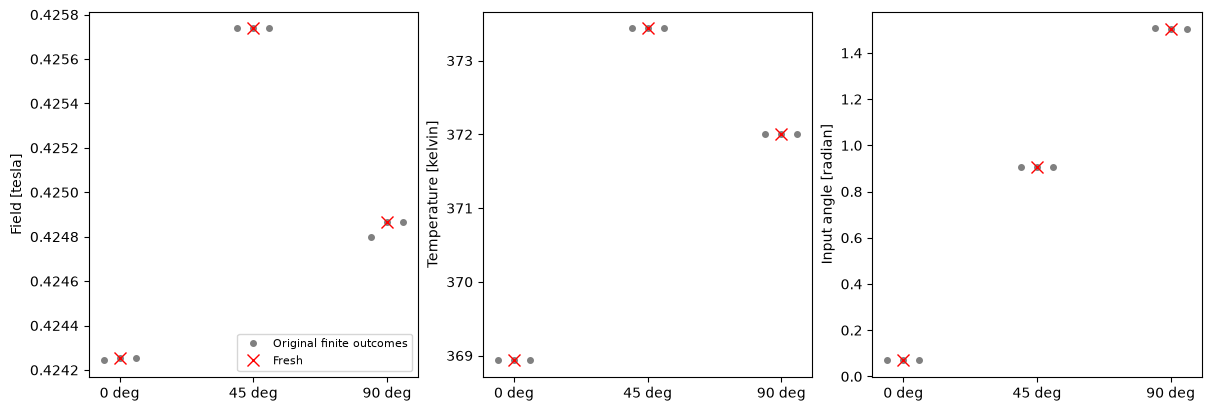

In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for j,(key,label,scale,offset) in enumerate([('magnetic_field','Field [tesla]',1e-4,0),('temperature','Temperature [kelvin]',1,273.15),('polarization','Input angle [radian]',1,0)]):
    for seed,shift in [(20261029,-.12),(20261030,0),(20261031,.12)]:
        vals=[original[f'parameters_{a}_{seed}'][0,j]*scale+offset for a in [0,45,90]]
        axes[j].plot(np.arange(3)+shift,vals,'o',ms=4,color='.5',label='Original finite outcomes' if seed==20261029 else None)
    axes[j].plot(range(3),fresh[key][0],'rx',ms=8,zorder=5,label='Fresh')
    axes[j].set(xticks=range(3),xticklabels=['0 deg','45 deg','90 deg'],ylabel=label)
axes[0].legend(fontsize=8);fig.savefig('output/elecsus_parameters.png',dpi=150);plt.show()


## Actual forward perturbation experiment

Independently perturb one fitted physical variable at a time while holding the other two fixed, recomputing the full native spectrum. This identifies their different spectral signatures: field moves/splits resonances, temperature changes density/broadening, and polarization reweights dielectric modes. These deliberate perturbations are supplemental model experiments, not fabricated comparison fits.

0 B +10 G full-native spectrum RMS change: 0.0009216056024407789
0 T +0.1 K full-native spectrum RMS change: 0.0007310217181847298
0 angle +0.01 rad full-native spectrum RMS change: 0.0003539952230130396
45 B +10 G full-native spectrum RMS change: 0.0024843321034847795
45 T +0.1 K full-native spectrum RMS change: 0.0006788597896133525
45 angle +0.01 rad full-native spectrum RMS change: 0.002748464213725742
90 B +10 G full-native spectrum RMS change: 0.0036096900631178465
90 T +0.1 K full-native spectrum RMS change: 0.0008469687492106436
90 angle +0.01 rad full-native spectrum RMS change: 0.00032233747379597024


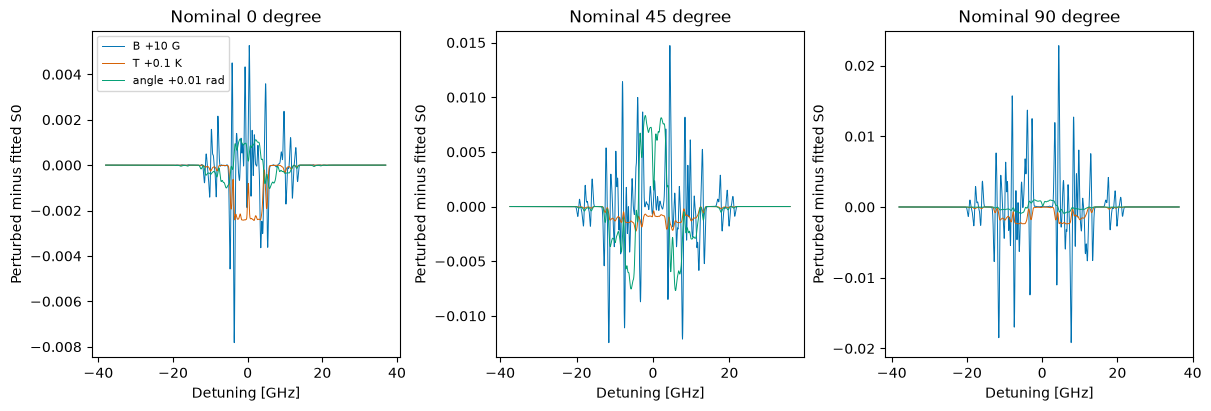

Conclusion: finite stochastic method support and observed spectral fit can be validated; actual B/T/angle truth and a physical confidence interval are unavailable.


In [4]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for i,angle in enumerate([0,45,90]):
    x,y=data[angle];b=fresh['magnetic_field'][0,i]*1e4;t=fresh['temperature'][0,i]-273.15;theta=fresh['polarization'][0,i]
    base=transmission(x,t,b,np.cos(theta),np.sin(theta))
    np.testing.assert_allclose(base,fresh[f'reconstruction_{angle}'][0],rtol=1e-12,atol=1e-12)
    for db,dt,da,label,color in [(10,0,0,'B +10 G','#0072B2'),(0,.1,0,'T +0.1 K','#D55E00'),(0,0,.01,'angle +0.01 rad','#009E73')]:
        altered=transmission(x,t+dt,b+db,np.cos(theta+da),np.sin(theta+da))
        axes[i].plot(x/1000,altered-base,color=color,lw=.7,label=label)
        print(angle,label,'full-native spectrum RMS change:',np.sqrt(np.mean((altered-base)**2)))
    axes[i].set(xlabel='Detuning [GHz]',ylabel='Perturbed minus fitted S0',title=f'Nominal {angle} degree')
axes[0].legend(fontsize=8);fig.savefig('output/elecsus_sensitivity.png',dpi=150);plt.show()
print('Conclusion: finite stochastic method support and observed spectral fit can be validated; actual B/T/angle truth and a physical confidence interval are unavailable.')
